# ALA: conformations by torsion partitioning

The conformations of alanine dipeptide in the 1 us cMD run, found by cutting the free-energy profiles of phi
and psi at their barriers ([torsion partitioning](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-partitioning/),
`cut_clustering`, at its defaults: 1 kT, 0.1 %, cuts at least 60 degrees apart), and compared with
[HDBSCAN](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/hdbscan/). How the torsions are prepared
is on [Torsion preprocessing](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/);
for phi and psi it changes nothing, since no symmetry operation of the molecule moves them.

**A cluster is a region bounded by barriers, not a metastable state.** Nothing here looks at time.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "_analysis"))   # docs/tutorial/_analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
import tutorial_data as td
import md_tools
from md_tools.analysis import (t_hdbscan, cut_clustering, plot_split_tree, plot_hist,
                               TorsionDefinitions, verify_atom_mapping)

print("tutorial runs:", "found" if td.runs_root().is_dir() else "MISSING", "| md-tools", md_tools.__version__)

tutorial runs: found | md-tools 0.6.5.2


## 1. The torsions

All 100 000 frames. The molecule is built from the run's own topology (there is no SDF for a peptide built
from a sequence), so the atom mapping is the identity.

In [2]:
traj = td.solute("ALA-1us")
mol = td.molecule_from_topology(traj)
mapping, why = verify_atom_mapping(mol, [(a.index, b.index) for a, b in traj.topology.bonds],
                                   [a.element.symbol for a in traj.topology.atoms])
phi_atoms, phi = md.compute_phi(traj)
psi_atoms, psi = md.compute_psi(traj)
definitions = TorsionDefinitions(quads=(tuple(phi_atoms[0]), tuple(psi_atoms[0])), names=("phi", "psi"),
                                 indexing="zero-based", units="radian")
tors = np.column_stack([phi[:, 0], psi[:, 0]])
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=traj, atom_mapping=mapping)
print(f"{len(tors)} frames | {why}")

100000 frames | identity verified: elements and the full bond graph agree under this mapping


## 2. Torsion partitioning

In [3]:
result = cut_clustering(fit)
print("\n".join(result["log"]))

100000 frames: periodic cut on phi (empty bins) -> 2759 + 97241
  2759 frames: periodic cut on psi (empty bins) -> 2574 + 185
  97241 frames: periodic cut on psi (barrier 3.39 kT at E*=2.93) -> 29832 + 67409
    67409 frames: bounded cut on phi (barrier 1.15 kT at E*=1.00) -> 12812 + 54597


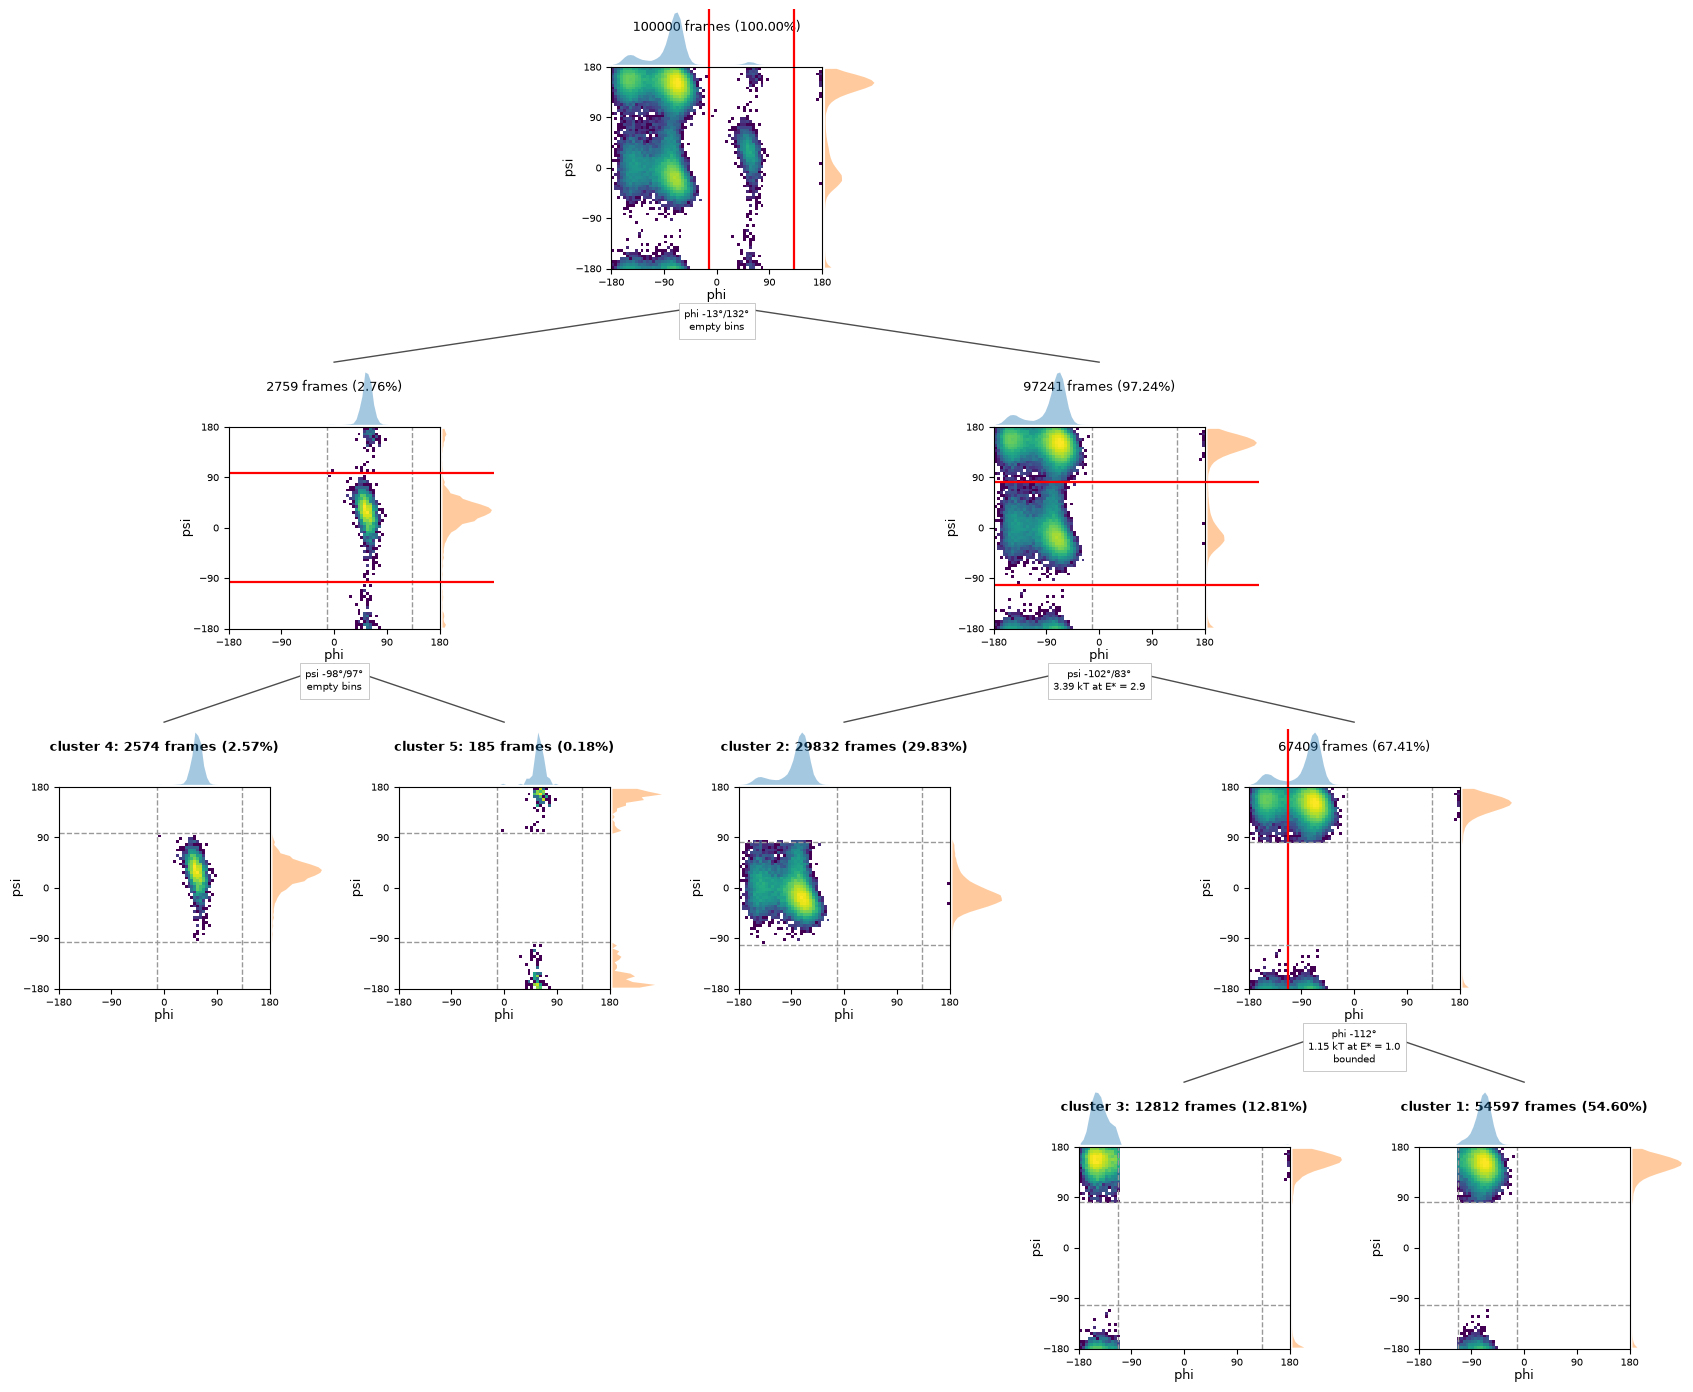

In [4]:
plot_split_tree(result, pair=("phi", "psi"));

Each panel is one cell: the 2D histogram of its frames (log counts) with the phi density on top and the psi
density on the right, the cut made there in red and the boundaries it inherited in grey. Two cuts through
empty bins come first; then psi at 3.39 kT separates alpha-R, and a bounded phi cut at 1.15 kT, inside the
arc the first phi cut left, separates beta from PPII.

In [5]:
def circular_mean(x):
    return float(np.degrees(np.angle(np.exp(1j * x).mean())))

names = {}
for c in range(result["n_clusters"]):
    m = result["labels"] == c
    names[c] = {"cluster": c + 1, "frames": int(m.sum()), "mass (%)": round(100 * result["cluster_mass"][c], 2),
                "phi (deg)": round(circular_mean(tors[m, 0])), "psi (deg)": round(circular_mean(tors[m, 1]))}
table = pd.DataFrame(names.values())
table["region"] = ["PPII", "alpha-R", "beta", "alpha-L", "phi > 0, psi near 180"]
table

,cluster,frames,mass (%),phi (deg),psi (deg),region
0,1,54597,54.60,-71,149,PPII
1,2,29832,29.83,-83,-11,alpha-R
2,3,12812,12.81,-144,156,beta
3,4,2574,2.57,56,27,alpha-L
4,5,185,0.18,59,179,"phi > 0, psi near 180"


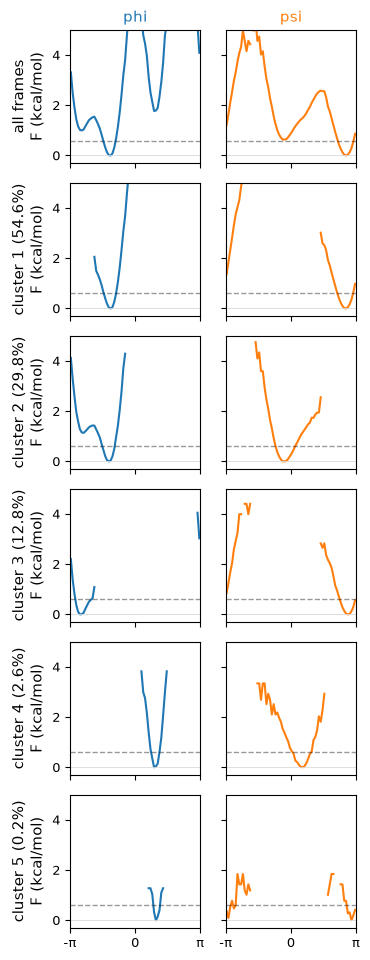

In [6]:
plot_hist(result, n_cluster=5, show_molecule=False);

The free energy of phi and psi in each cluster, in kcal/mol at 300 K, the dashed line at the 1 kT cut.

## 3. Against HDBSCAN

HDBSCAN fits an exact distance matrix, so at most 10 000 frames: 4000 drawn from the run
(`resampling=4000`), then every frame classified by the 18-of-20 vote. Its defaults are a 1 % floor and
`min_samples` 40.

In [7]:
hdb = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=traj, atom_mapping=mapping,
                resampling=4000).fit()
name = lambda c: {-2: "noise", -1: "ambiguous"}.get(c, f"HDBSCAN {c}")
cross = pd.crosstab(pd.Series([f"cell {c + 1}" for c in result["labels"]], name="torsion partitioning"),
                    pd.Series([name(c) for c in hdb.labels_], name="HDBSCAN"))
print(f"HDBSCAN: {hdb.n_clusters_} clusters, noise {100 * hdb.noise_mass_:.2f} %, ambiguous {100 * hdb.ambiguous_mass_:.2f} %")
cross

HDBSCAN: 4 clusters, noise 0.29 %, ambiguous 1.22 %


HDBSCAN,HDBSCAN 0,HDBSCAN 1,HDBSCAN 2,HDBSCAN 3,ambiguous,noise
torsion partitioning,,,,,,
cell 1,54454,8,0,0,131,4
cell 2,0,29791,0,0,24,17
cell 3,289,6,11451,0,1061,5
cell 4,0,0,0,2497,0,77
cell 5,0,0,0,0,0,185


The four large clusters are the same in both up to their borders, where HDBSCAN calls frames ambiguous or
noise and the torsion partitioning puts every frame on one side of a cut. The borders differ most between beta
and PPII, the lowest barrier (1.15 kT): of the 12 812 frames of cell 3, 289 are PPII to HDBSCAN and 1061
ambiguous. The 0.18 % strip is below HDBSCAN's 1 % floor and all 185 of its frames are noise there; the cell
partitioning keeps it, because a
run of empty bins separates it and it holds more than 0.1 % of the frames. Whether it is a state is a
question about the sampling: 185 frames of a 1 us run.